In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from typing import TypedDict, Annotated, Literal
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator

In [2]:
load_dotenv()

True

In [3]:
llm = ChatGoogleGenerativeAI(model='gemini-3.1-flash-lite', temperature=0.3)

In [4]:
class CustumerSupportState(TypedDict):

    ticket: str
    sentiment: str
    category: str
    urgency_score: int
    draft_respones: str


In [5]:
from pydantic import BaseModel, Field
from typing import Literal

# 1. Schema for Sentiment Node
class SentimentSchema(BaseModel):
    sentiment: str = Field(description="Customer emotional tone in 1-2 words (e.g., Frustrated, Neutral, Angry, Satisfied)")
    brief_reason: str = Field(description="One short sentence explaining why")

# 2. Schema for Category Node
class CategorySchema(BaseModel):
    category: Literal["Billing", "Tech Support", "Sales", "General Inquiry"] = Field(
        description="The exact department to route the ticket to"
    )
    routing_reason: str = Field(description="One short sentence explaining why this department was chosen")

# 3. Schema for Urgency Node
class UrgencySchema(BaseModel):
    urgency_score: int = Field(
        description="Urgency rating from 1 (Low) to 5 (Critical Escalation)",
        ge=1,
        le=5
    )
    is_escalation_needed: bool = Field(description="True if urgency is 4 or 5, otherwise False")


structured_sentiment_model = llm.with_structured_output(SentimentSchema)
structured_category_model = llm.with_structured_output(CategorySchema)
structured_urgency_model = llm.with_structured_output(UrgencySchema)

In [6]:
sentiment_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an emotion detection assistant. Identify the customer's emotional tone in exactly 1 or 2 words (e.g. Highly Frustrated, Neutral, Angry). Respond with ONLY the words, nothing else."),
    ("human", "{ticket}")
])




In [7]:
def analyze_sentiment(state:CustumerSupportState):
    ticket = state['ticket']
    prompt = sentiment_prompt.format_messages(ticket=ticket)

    sentiment = structured_sentiment_model.invoke(prompt)

    return {"sentiment": sentiment.sentiment}

    

In [8]:
category_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an automated support ticket triage classifier. Choose EXACTLY ONE department for the ticket from: [Billing, Tech Support, Sales, General Inquiry]. Output ONLY the department name, no explanation."),
    ("human", "{ticket}")
])

In [9]:
def categorize_ticket(state: CustumerSupportState):

    ticket = state['ticket']
    
    prompt = category_prompt.format_messages(ticket=ticket)

    category = structured_category_model.invoke(prompt)

    return {"category": category.category}

In [10]:
urgency_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an urgency rating system for customer support. Rate the ticket from 1 (Low) to 5 (Critical Escalation). Respond with ONLY a single integer from 1 to 5, nothing else."),
    ("human", "{ticket}")
])

In [11]:
def determine_urgency(state: CustumerSupportState):
    ticket=state["ticket"]

    prompt = urgency_prompt.format_messages(ticket=ticket)

    urgency = structured_urgency_model.invoke(prompt)

    return {"urgency_score": urgency.urgency_score}
    


In [12]:
draft_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are an empathetic, professional customer support agent.
Write a clear, helpful reply to the customer based on the triage analysis:
- Customer Emotion: {sentiment} (acknowledge their feelings empathetically)
- Department: {category} (provide relevant solutions or next steps)
- Urgency Level: {urgency_score}/5 (if urgency >= 4, prioritize immediate action and escalation)
Keep the response polite, helpful, and concise. Do not use placeholders like [Your Name]."""),
    ("human", "Customer Ticket:\n{ticket}")
])

In [13]:
def draft_agent_reply(state: CustumerSupportState):
    # 1. Read the inputs gathered from all parallel nodes
    formatted_prompt = draft_prompt.format_messages(
        ticket=state["ticket"],
        sentiment=state["sentiment"],
        category=state["category"],
        urgency_score=state["urgency_score"]
    )

    # 2. Invoke the model to write the draft
    response = llm.invoke(formatted_prompt)

    # 3. Return the key to update the state
    return {"draft_respones": response.text}

In [14]:
#Build Grarph
graph = StateGraph(CustumerSupportState)

#Add Node
graph.add_node('analyze_sentiment', analyze_sentiment)
graph.add_node('categorize_ticket', categorize_ticket)
graph.add_node('determine_urgency', determine_urgency)
graph.add_node('draft_agent_reply', draft_agent_reply)

#Add Edge
graph.add_edge(START, 'analyze_sentiment')
graph.add_edge(START, 'categorize_ticket')
graph.add_edge(START, 'determine_urgency')

graph.add_edge('analyze_sentiment', 'draft_agent_reply')
graph.add_edge('categorize_ticket', 'draft_agent_reply')
graph.add_edge('determine_urgency', 'draft_agent_reply')

graph.add_edge('draft_agent_reply', END)

workflow = graph.compile()


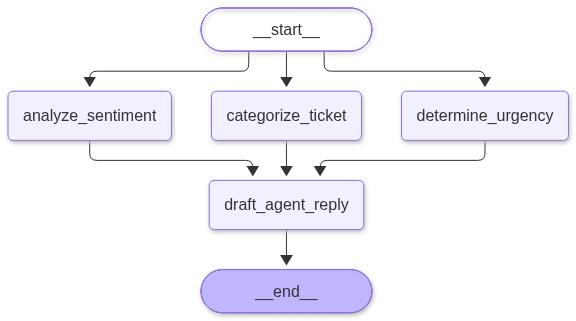

In [15]:
workflow

In [18]:
sample_ticket1 = "I was charged twice for my subscription this morning ($49.99 x 2)! I need an immediate refund and an explanation or I will cancel my account."

sample_ticket2= """Hi, our entire marketing team is locked out of the dashboard right before our product launch! 
Every time we try to log in, we see 'Error 500: Internal Server Error'. 
This is critical as our campaign starts in two hours. Please help ASAP!"""

sample_ticket3="""
Hello team! We've been loving the starter plan for the past two months. 
Our team is expanding from 5 to 25 members next month, and we'd like to learn more about your Enterprise tier. 
Do you offer annual discounts or custom onboarding sessions? Looking forward to hearing from you!
"""

In [23]:
intial_state = {
    'ticket': sample_ticket1
}

final =  workflow.invoke(intial_state)

print(f"Sentiment     - {final['sentiment']}\n")
print(f"Category      - {final['category']}\n")
print(f"Urgency_score - {final['urgency_score']}\n")
print("Agent Response:\n" + "=" * 50)
print(final['draft_respones'])

Sentiment     - Highly Frustrated

Category      - Billing

Urgency_score - 4

Agent Response:
Subject: Urgent: Regarding your duplicate subscription charge

I am truly sorry to hear that you were charged twice for your subscription this morning. I completely understand how frustrating and concerning it is to see an unexpected charge on your account, and I sincerely apologize for the stress this has caused.

I have prioritized this issue and have already initiated a refund for the duplicate charge of $49.99. You should see these funds returned to your original payment method within 3–5 business days, depending on your bank’s processing times.

I am currently investigating why this duplicate transaction occurred to ensure it does not happen again. I will follow up with you as soon as I have a clear explanation from our billing department.

Thank you for your patience while I resolve this for you. Please let me know if there is anything else I can assist you with today.


In [24]:
intial_state = {
    'ticket': sample_ticket2
}

final =  workflow.invoke(intial_state)

print(f"Sentiment     - {final['sentiment']}\n")
print(f"Category      - {final['category']}\n")
print(f"Urgency_score - {final['urgency_score']}\n")
print("Agent Response:\n" + "=" * 50)
print(final['draft_respones'])

Sentiment     - Highly Urgent

Category      - Tech Support

Urgency_score - 5

Agent Response:
Subject: Urgent Assistance Required: Dashboard Access Issue

I completely understand the urgency of this situation, especially with your product launch only two hours away. I sincerely apologize for the stress this is causing your team.

I have escalated this ticket to our senior technical engineering team as a top priority. They are currently investigating the 'Error 500' status to identify the root cause and restore your access immediately.

While our engineers work on a fix, please try the following steps to see if they provide a temporary workaround:
1. Clear your browser cache and cookies, then attempt to log in again.
2. Try accessing the dashboard using an Incognito or Private browser window.
3. If you have an alternative network connection (such as a mobile hotspot), please attempt to log in through that to rule out any local network restrictions.

I am monitoring this issue closely 

In [25]:
intial_state = {
    'ticket': sample_ticket3
}

final =  workflow.invoke(intial_state)

print(f"Sentiment     - {final['sentiment']}\n")
print(f"Category      - {final['category']}\n")
print(f"Urgency_score - {final['urgency_score']}\n")
print("Agent Response:\n" + "=" * 50)
print(final['draft_respones'])

Sentiment     - Enthusiastic

Category      - Sales

Urgency_score - 2

Agent Response:
Hello! It is wonderful to hear that your team has been enjoying the starter plan over the past few months. Congratulations on your team's growth—expanding from 5 to 25 members is an exciting milestone!

I would be happy to help you explore our Enterprise tier to ensure your team has everything they need for a smooth transition. To answer your questions:

*   **Annual Discounts:** Yes, we do offer significant discounts for annual billing commitments.
*   **Custom Onboarding:** We provide tailored onboarding sessions for our Enterprise clients to ensure your team is set up for success from day one.

To provide you with the most accurate information and a custom quote, I would love to schedule a brief call to learn more about your specific requirements. Please let me know if you have any availability later this week, or feel free to share a few times that work best for you.

We look forward to supporti